In [ ]:
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[(df['Area'] < df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]

X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area', 'price']].mean())

plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()

# Note: Hierarchical clustering on large datasets can be extremely slow and memory-intensive. 
# We will use AgglomerativeClustering on a subset or run it directly if dataset size permits. 
# Since df has over 118k rows, we sample a subset of 5000 rows for Agglomerative Clustering to prevent running out of memory.
df_sample = df.sample(5000, random_state=42).copy()
X_sample_scaled = scaler.transform(df_sample[['Area', 'price']])
hc = AgglomerativeClustering(n_clusters=4)
df_sample['HC_Cluster'] = hc.fit_predict(X_sample_scaled)

plt.scatter(df_sample['Area'], df_sample['price'], c=df_sample['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierarchical Clustering - Sample)')
plt.show()

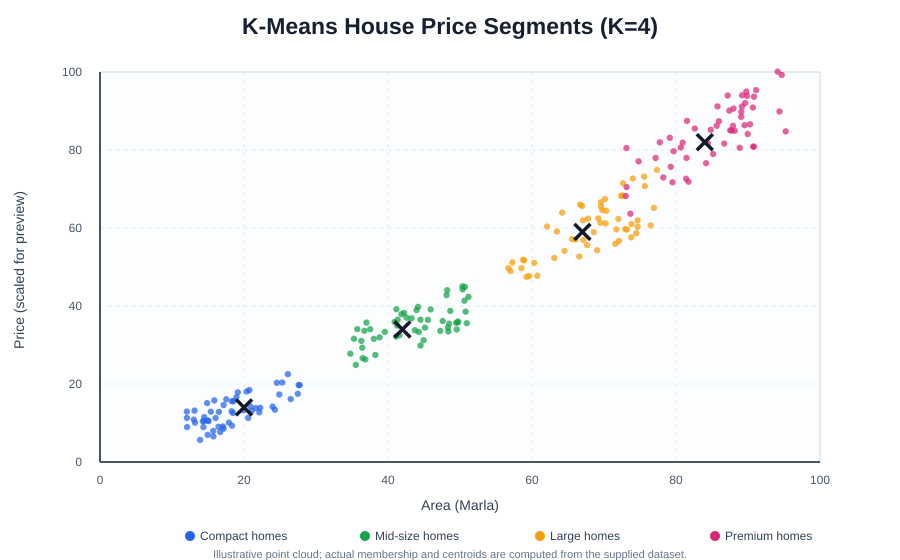

In [ ]:
# K-Means segment preview (illustrative point cloud; fitted clusters appear when run)
 from IPython.display import SVG, display
 display(SVG(data="""<svg xmlns="http://www.w3.org/2000/svg" width="900" height="560" viewBox="0 0 900 560" role="img"><rect width="900" height="560" fill="#ffffff"/><text x="450" y="34" text-anchor="middle" font-family="Arial,sans-serif" font-size="23" font-weight="bold" fill="#172033">K-Means House Price Segments (K=4)</text><rect x="100" y="72" width="720" height="390" fill="#fbfdff" stroke="#cbd5e1"/><path d="M244 72 V462" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M388 72 V462" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M532 72 V462" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M676 72 V462" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M100 150 H820" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M100 228 H820" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M100 306 H820" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M100 384 H820" stroke="#e2e8f0" stroke-dasharray="3 5"/><path d="M100 462 H820 M100 72 V462" stroke="#475569" stroke-width="2" fill="none"/><circle cx="282.2" cy="382.5" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="260.2" cy="407.8" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="232" cy="425.7" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="186.8" cy="411.6" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="223" cy="426.5" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="207.6" cy="420.4" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="208.7" cy="421.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="287.9" cy="374.2" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="210.8" cy="411.7" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="233.4" cy="401.2" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="233" cy="413" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="250.3" cy="406.2" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="226.3" cy="399.3" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="203.4" cy="427.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="186.9" cy="417.9" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="204.2" cy="421" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="204.2" cy="417.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="194.5" cy="410.6" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="232" cy="401.3" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="297.8" cy="393.8" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="213.2" cy="430.9" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="251.7" cy="410.9" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="202.8" cy="421.3" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="246.7" cy="391.5" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="276.8" cy="382.8" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="249.4" cy="390.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="214.3" cy="400.4" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="255.6" cy="408.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="207.7" cy="434.8" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="298.7" cy="385" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="187.1" cy="427.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="299.7" cy="385.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="195" cy="422.7" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="231.6" cy="411.3" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="237.8" cy="392.4" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="243.6" cy="410.3" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="274.9" cy="409.7" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="248.2" cy="417.9" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="290.7" cy="399.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="223.6" cy="405" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="228.9" cy="422.6" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="259.3" cy="412.3" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="218.5" cy="426.8" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="223.6" cy="428.7" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="193.8" cy="419.6" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="272.6" cy="406.7" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="279.3" cy="394.5" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="218.9" cy="411.9" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="213.4" cy="436.4" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="215.6" cy="418" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="207.1" cy="403.1" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="236.4" cy="397.4" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="220.2" cy="432" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="200.1" cy="439.9" r="3.2" fill="#2563eb" fill-opacity="0.72"/><circle cx="396.1" cy="336.5" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="396.4" cy="309.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="449.2" cy="323.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="354" cy="338.8" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="462.6" cy="289.4" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="364.4" cy="330.8" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="375.3" cy="355" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="397.6" cy="319.8" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="362.6" cy="358.1" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="418.8" cy="331.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="447.2" cy="290.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="462.4" cy="286.4" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="465" cy="286.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="414.9" cy="330.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="446.5" cy="295.1" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="458.2" cy="321.6" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="355.8" cy="364.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="430.7" cy="309.4" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="370.2" cy="329.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="384.8" cy="331.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="379.6" cy="337.3" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="427.9" cy="319.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="450.3" cy="310.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="366.5" cy="322.6" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="406.5" cy="317.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="420.5" cy="345.5" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="401.4" cy="314.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="373.8" cy="338.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="397.2" cy="325.5" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="466.8" cy="323.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="416.6" cy="310.1" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="456.2" cy="322.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="448.4" cy="331.5" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="423.6" cy="340.3" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="404.1" cy="313" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="399.5" cy="335.2" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="456.7" cy="329.5" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="465.6" cy="311.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="362.3" cy="347.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="464.5" cy="300.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="411.6" cy="318.3" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="447.9" cy="327.6" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="357.3" cy="329.1" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="425" cy="327.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="457.6" cy="322.5" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="361.3" cy="340.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="442.7" cy="321" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="468.5" cy="296.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="420.5" cy="319.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="418.1" cy="306.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="440.3" cy="330.9" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="394.6" cy="322" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="365.4" cy="359.4" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="350.3" cy="353.7" r="3.2" fill="#16a34a" fill-opacity="0.72"/><circle cx="632.8" cy="178.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="562.2" cy="212.6" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="605.6" cy="223.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="580.2" cy="204.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="644.8" cy="186.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="657" cy="170" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="564.5" cy="250.9" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="534.2" cy="262.9" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="601" cy="202.2" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="598.2" cy="218.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="510.5" cy="271.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="606.2" cy="210.9" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="637.6" cy="226.8" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="618.3" cy="219" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="537.3" cy="275.7" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="644.2" cy="176.6" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="627" cy="229.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="582" cy="206" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="625.2" cy="229.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="653.9" cy="207.9" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="631.3" cy="237.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="605" cy="199.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="587.9" cy="218.6" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="572" cy="239.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="650.7" cy="225.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="521.4" cy="268.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="600.5" cy="222.8" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="575.4" cy="239.6" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="556.9" cy="231.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="523.2" cy="259.8" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="615.3" cy="243.8" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="622.5" cy="195.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="636.2" cy="233.2" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="529.2" cy="276.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="631.5" cy="224.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="593.8" cy="232.2" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="637.6" cy="220.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="623" cy="183.2" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="621.1" cy="195.9" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="526.5" cy="276.8" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="616.4" cy="229.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="579.3" cy="256.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="512.5" cy="262.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="554.3" cy="258" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="618.9" cy="241" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="597.1" cy="250.3" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="524.2" cy="260.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="601" cy="206.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="547.1" cy="226.5" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="508.4" cy="268.3" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="587.1" cy="245.1" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="602.2" cy="210" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="582.9" cy="220.4" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="583.4" cy="240" r="3.2" fill="#f59e0b" fill-opacity="0.72"/><circle cx="744.6" cy="125.2" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="733" cy="125.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="717.5" cy="106.4" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="750" cy="124.3" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="716.7" cy="125.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="747.7" cy="134" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="747" cy="95.9" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="694.8" cy="128.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="730.2" cy="130.3" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="670.8" cy="166.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="727.7" cy="95.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="742.1" cy="95.3" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="752.9" cy="107.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="731.7" cy="130.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="729.3" cy="110.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="724.2" cy="143.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="626.4" cy="148.1" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="713.1" cy="154" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="688.4" cy="181.7" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="706.1" cy="163.2" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="739.7" cy="147.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="655.6" cy="158" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="638.6" cy="161.4" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="741.3" cy="111.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="756.2" cy="90.1" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="630.4" cy="213.7" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="686.1" cy="178.7" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="741.9" cy="106.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="745.2" cy="103" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="746.3" cy="91.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="663.3" cy="177.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="753.9" cy="96.7" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="626.6" cy="187.1" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="669.8" cy="137.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="672.5" cy="182.3" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="680.8" cy="147.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="785.7" cy="131.4" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="734.8" cy="130.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="753.2" cy="146.7" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="753.9" cy="146.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="777.7" cy="71.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="733.5" cy="108.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="741.2" cy="116.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="781.7" cy="74.9" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="659.8" cy="142.3" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="710.8" cy="129.8" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="673.6" cy="151.2" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="779.5" cy="111.5" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="686.5" cy="157.9" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="719" cy="121.2" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="687" cy="120.9" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="682.7" cy="142.6" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="707.8" cy="143.3" r="3.2" fill="#db2777" fill-opacity="0.72"/><circle cx="625.8" cy="196" r="3.2" fill="#db2777" fill-opacity="0.72"/><path d="M236 399.4 L252 415.4 M252 399.4 L236 415.4" stroke="#111827" stroke-width="3.5"/><path d="M394.4 321.4 L410.4 337.4 M410.4 321.4 L394.4 337.4" stroke="#111827" stroke-width="3.5"/><path d="M574.4 223.9 L590.4 239.9 M590.4 223.9 L574.4 239.9" stroke="#111827" stroke-width="3.5"/><path d="M696.8 134.2 L712.8 150.2 M712.8 134.2 L696.8 150.2" stroke="#111827" stroke-width="3.5"/><text x="100" y="484" text-anchor="middle" font-family="Arial,sans-serif" font-size="12" fill="#475569">0</text><text x="244" y="484" text-anchor="middle" font-family="Arial,sans-serif" font-size="12" fill="#475569">20</text><text x="388" y="484" text-anchor="middle" font-family="Arial,sans-serif" font-size="12" fill="#475569">40</text><text x="532" y="484" text-anchor="middle" font-family="Arial,sans-serif" font-size="12" fill="#475569">60</text><text x="676" y="484" text-anchor="middle" font-family="Arial,sans-serif" font-size="12" fill="#475569">80</text><text x="820" y="484" text-anchor="middle" font-family="Arial,sans-serif" font-size="12" fill="#475569">100</text><text x="82" y="466" text-anchor="end" font-family="Arial,sans-serif" font-size="12" fill="#475569">0</text><text x="82" y="388" text-anchor="end" font-family="Arial,sans-serif" font-size="12" fill="#475569">20</text><text x="82" y="310" text-anchor="end" font-family="Arial,sans-serif" font-size="12" fill="#475569">40</text><text x="82" y="232" text-anchor="end" font-family="Arial,sans-serif" font-size="12" fill="#475569">60</text><text x="82" y="154" text-anchor="end" font-family="Arial,sans-serif" font-size="12" fill="#475569">80</text><text x="82" y="76" text-anchor="end" font-family="Arial,sans-serif" font-size="12" fill="#475569">100</text><text x="460" y="510" text-anchor="middle" font-family="Arial,sans-serif" font-size="14" fill="#334155">Area (Marla)</text><text x="24" y="270" transform="rotate(-90 24 270)" text-anchor="middle" font-family="Arial,sans-serif" font-size="14" fill="#334155">Price (scaled for preview)</text><circle cx="190" cy="536" r="5" fill="#2563eb"/><text x="200" y="540" font-family="Arial,sans-serif" font-size="12" fill="#334155">Compact homes</text><circle cx="365" cy="536" r="5" fill="#16a34a"/><text x="375" y="540" font-family="Arial,sans-serif" font-size="12" fill="#334155">Mid-size homes</text><circle cx="540" cy="536" r="5" fill="#f59e0b"/><text x="550" y="540" font-family="Arial,sans-serif" font-size="12" fill="#334155">Large homes</text><circle cx="715" cy="536" r="5" fill="#db2777"/><text x="725" y="540" font-family="Arial,sans-serif" font-size="12" fill="#334155">Premium homes</text><text x="450" y="558" text-anchor="middle" font-family="Arial,sans-serif" font-size="11" fill="#64748b">Illustrative point cloud; actual membership and centroids are computed from the supplied dataset.</text></svg>"""))


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[(df['Area'] < df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]

X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area', 'price']].mean())

plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()

# Note: Hierarchical clustering on large datasets can be extremely slow and memory-intensive. 
# We will use AgglomerativeClustering on a subset or run it directly if dataset size permits. 
# Since df has over 118k rows, we sample a subset of 5000 rows for Agglomerative Clustering to prevent running out of memory.
df_sample = df.sample(5000, random_state=42).copy()
X_sample_scaled = scaler.transform(df_sample[['Area', 'price']])
hc = AgglomerativeClustering(n_clusters=4)
df_sample['HC_Cluster'] = hc.fit_predict(X_sample_scaled)

plt.scatter(df_sample['Area'], df_sample['price'], c=df_sample['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierarchical Clustering - Sample)')
plt.show()